<a href="https://colab.research.google.com/github/Maddox159-crypto/2026_ESAA_assignment/blob/main/%ED%95%84%EC%82%AC38.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[개념]

### 1. LSTM 구조와 작동 원리
- **LSTM**: 기존 RNN의 기울기 소멸 문제를 완화하고 장기적인 정보를 기억하기 위한 모델.
- **망각 게이트**: 과거 정보 중 유지하거나 삭제할 정보를 결정.
- **입력 게이트**: 현재 입력 정보 중 새롭게 기억할 정보를 결정.
- **셀 상태**: 망각 게이트와 입력 게이트의 결과를 반영하여 기억을 갱신.
- **출력 게이트**: 갱신된 셀 상태를 바탕으로 현재 은닉 상태를 결정.
- **역전파**: 셀 상태를 통해 기울기를 전달하여 기울기 소멸 문제를 완화.


---


### 2. LSTM 셀 구현
- **LSTMCell**: 현재 입력과 이전 은닉 상태 및 셀 상태를 이용하여 새로운 상태를 계산.
- **nn.Linear()**: 입력과 은닉 상태에 가중치를 적용하여 게이트 값을 계산.
- **torch.chunk(4, 1)**: 텐서를 입력,망각,셀,출력 게이트에 해당하는 네 부분으로 분할.
- **Sigmoid / Tanh**: Sigmoid는 정보 통과 비율을, Tanh는 셀에 반영할 값과 출력을 조정.
- **torch.mul()**: 텐서의 원소별 곱셈으로 셀 상태를 갱신.
- **MNIST 실습**: 손글씨 숫자를 분류하는 LSTM 셀 기반 모델을 구현하여 약 98%의 정확도를 확인.


---


### 3. LSTM 계층 구현 및 시계열 예측
- **nn.LSTM()**: 여러 시점의 데이터를 순차적으로 처리하는 PyTorch의 LSTM 계층.
- **주요 파라미터**: input_size(입력 특성 수), hidden_size(은닉 유닛 수), num_layers(계층 수), batch_first(배치 우선 여부).
- **데이터 전처리**: 날짜 인덱스 설정, 자료형 변환, StandardScaler·MinMaxScaler를 이용한 스케일링.
- **텐서 변환**: 데이터를 (batch_size, seq_length, input_size) 형태로 변환.
- **모델 학습**: MSELoss와 Adam을 이용하여 예측 오차를 최소화.
- **주가 예측 실습**: 스타벅스 주가 데이터로 거래량(Volume)을 예측하고 실제값과 예측값을 비교.

[필사]

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

In [2]:
import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [3]:
from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET'

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.89MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.55MB/s]


In [4]:
batch_size = 64
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset=test_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=True)

In [5]:
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [6]:
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(LSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self):
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, hidden):
        hx, cx = hidden
        x = x.view(-1, x.size(1))

        gates = self.x2h(x) + self.h2h(hx)
        gates = gates.squeeze()
        ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

        ingate = F.sigmoid(ingate)
        forgetgate = F.sigmoid(forgetgate)
        cellgate = F.tanh(cellgate)
        outgate = F.sigmoid(outgate)

        cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
        hy = torch.mul(outgate, F.tanh(cy))
        return(hy, cy)

In [7]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
        super(LSTMModel, self).__init__()
        self.hidden_dim = hidden_dim

        self.layer_dim = layer_dim
        self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        if torch.cuda.is_available():
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
        else:
            h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

        if torch.cuda.is_available():
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
        else:
            c0 = Variable(torch.zeros(self.layer_dim, x.size(0), hidden_dim))

        outs = []
        cn = c0[0,:,:]
        hn = h0[0,:,:]

        for seq in range(x.size(1)):
            hn, cn = self.lstm(x[:,seq,:], (hn,cn))
            outs.append(hn)

        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

In [8]:
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available():
    model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [10]:
from torch.autograd import Variable

In [11]:
seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = Variable(labels.cuda())
        else:
            images = Variable(images.view(-1, seq_dim, input_dim))
            labels = Variable(labels)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        if torch.cuda.is_available():
            loss.cuda()

        loss.backward()
        optimizer.step()
        loss_list.append(loss.item())
        iter += 1

        if iter % 500 == 0:
            correct = 0
            total = 0
            for images, labels in valid_loader:

                if torch.cuda.is_available():
                    images = Variable(images.view(-1, seq_dim, input_dim).cuda())
                else:
                    images = Variable(images.view(-1, seq_dim, input_dim))

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                if torch.cuda.is_available():
                    correct += (predicted.cpu() == labels.cpu()).sum()
                else:
                    correct += (predicted == labels).sum()

            accuracy = 100 * correct / total
            print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(),
                  accuracy))

Iteration: 500. Loss: 2.263226270675659. Accuracy: 18.860000610351562
Iteration: 1000. Loss: 0.8081591725349426. Accuracy: 74.4800033569336
Iteration: 1500. Loss: 0.2894662320613861. Accuracy: 89.13999938964844
Iteration: 2000. Loss: 0.5361144542694092. Accuracy: 93.0199966430664
Iteration: 2500. Loss: 0.15865935385227203. Accuracy: 94.47000122070312
Iteration: 3000. Loss: 0.1577019840478897. Accuracy: 96.5199966430664
Iteration: 3500. Loss: 0.1396593451499939. Accuracy: 96.69999694824219
Iteration: 4000. Loss: 0.19647923111915588. Accuracy: 96.62000274658203
Iteration: 4500. Loss: 0.05438874289393425. Accuracy: 97.06999969482422
Iteration: 5000. Loss: 0.039444439113140106. Accuracy: 97.37000274658203
Iteration: 5500. Loss: 0.02017313241958618. Accuracy: 97.79000091552734
Iteration: 6000. Loss: 0.07331443578004837. Accuracy: 97.66000366210938
Iteration: 6500. Loss: 0.06266807019710541. Accuracy: 97.2699966430664
Iteration: 7000. Loss: 0.06563063710927963. Accuracy: 97.93000030517578
It

In [12]:
def evaluate(model, val_iter):
    corrects, total, total_loss = 0, 0, 0
    model.eval()

    for images, labels in val_iter:
        if torch.cuda.is_available():
            images = Variable(images.view(-1, seq_dim, input_dim).cuda())
            labels = labels.cuda()
        else:
            images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
            labels = labels.to(device)

        logit = model(images).to(device)
        loss = F.cross_entropy(logit, labels, reduction="sum")
        _, predicted = torch.max(logit.data, 1)

        total += labels.size(0)
        total_loss += loss.item()
        corrects += (predicted == labels).sum()

    avg_loss = total_loss / len(val_iter.dataset)
    avg_accuracy = corrects / total
    return avg_loss, avg_accuracy

In [13]:
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f : Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.08 : Test Accuracy:  0.98


In [14]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [15]:
import pandas as pd
url = "https://raw.githubusercontent.com/gilbutITbook/080289/main/chap07/data/SBUX.csv"
data = pd.read_csv(url)
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


In [16]:
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

In [17]:
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]

print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
              Volume
Date                
2019-12-11 

In [18]:
ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [20]:
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(
    X_train_tensors,
    (X_train_tensors.shape[0], 1, X_train_tensors.shape[1])
)

X_test_tensors_f = torch.reshape(
    X_test_tensors,
    (X_test_tensors.shape[0], 1, X_test_tensors.shape[1])
)

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


In [21]:
class LSTM(nn.Module):
    def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
        super(LSTM, self).__init__()

        self.num_classes = num_classes
        self.num_layers = num_layers
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.seq_length = seq_length

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc_1 = nn.Linear(hidden_size, 128)
        self.fc = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        h_0 = Variable(torch.zeros(
            self.num_layers, x.size(0), self.hidden_size
        ))

        c_0 = Variable(torch.zeros(
            self.num_layers, x.size(0), self.hidden_size
        ))

        output, (hn, cn) = self.lstm(x, (h_0, c_0))
        hn = hn.view(-1, self.hidden_size)
        out = self.relu(hn)

        out = self.fc_1(out)
        out = self.relu(out)
        out = self.fc(out)

        return out

In [22]:
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1

num_classes = 1

model = LSTM(
    num_classes,
    input_size,
    hidden_size,
    num_layers,
    X_train_tensors_f.shape[1]
)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [23]:
for epoch in range(num_epochs):
    outputs = model.forward(X_train_tensors_f)
    optimizer.zero_grad()

    loss = criterion(outputs, y_train_tensors)
    loss.backward()

    optimizer.step()

    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.22602
Epoch: 100, loss: 0.06871
Epoch: 200, loss: 0.03774
Epoch: 300, loss: 0.03395
Epoch: 400, loss: 0.03218
Epoch: 500, loss: 0.03053
Epoch: 600, loss: 0.02901
Epoch: 700, loss: 0.02768
Epoch: 800, loss: 0.02639
Epoch: 900, loss: 0.02505


In [24]:
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))

df_x_ss = torch.reshape(
    df_x_ss,
    (df_x_ss.shape[0], 1, df_x_ss.shape[1])
)

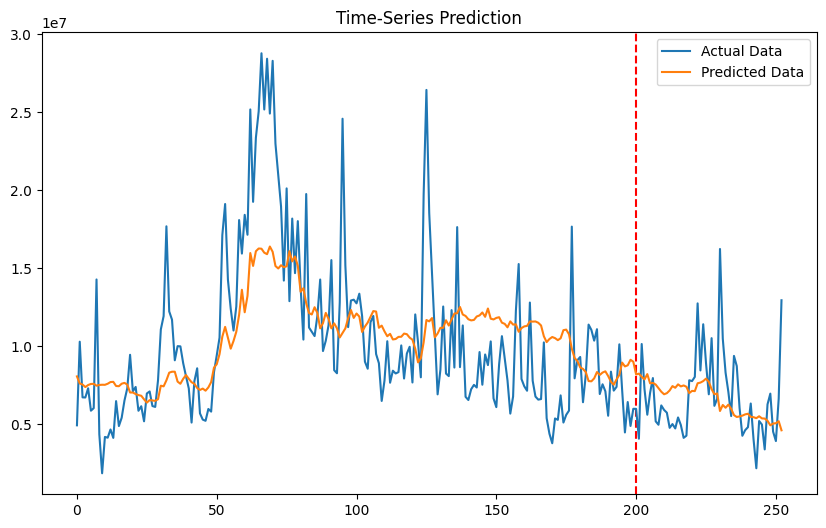

In [25]:
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)

plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()